# Customer Churn & Revenue Analysis
**Tools:** pandas · NumPy · matplotlib

## 1. Business Problem
A subscription company (telecom / streaming / SaaS) is losing customers every month.
Management wants answers to four questions:
1. **How bad is churn?** (churn rate, revenue lost)
2. **Who is leaving?** (contract, tenure, payment method, service type)
3. **Can we flag at-risk customers early?** (risk score)
4. **What should we do about it?** (recommendations + estimated savings)

> **Note on data:** `telco_churn.csv` is a synthetic dataset that mimics the structure of the Kaggle *Telco Customer Churn* dataset (same columns, same data-quality quirks). You can swap in the real file without changing any code.

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## 3. Load the Data

In [2]:
df = pd.read_csv("../data/telco_churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7058, 20)


,customerID,gender,SeniorCitizen,Partner,Dependents,Contract,tenure,PhoneService,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,PaymentMethod,MonthlyCharges,Churn,TotalCharges
0,1803-URLLW,Male,0,No,No,Two year,46,Yes,DSL,Yes,No,No,No,No,Yes,Yes,Bank transfer (automatic),77.86,No,3663.19
1,1773-SFCNZ,Male,0,No,Yes,Two year,41,Yes,DSL,Yes,No,Yes,No,Yes,No,Yes,Electronic check,74.55,No,3117.54
2,7621-TSUND,Male,0,Yes,No,Month-to-month,22,Yes,DSL,No,Yes,Yes,No,Yes,Yes,Yes,Electronic check,80.71,Yes,1809.17
3,8556-LNJEY,Female,1,No,Yes,Month-to-month,19,Yes,DSL,No,No,No,No,Yes,Yes,No,Credit card (automatic),84.05,No,1639.7
4,8033-QKVOL,Male,0,Yes,No,One year,30,Yes,Fiber optic,No,No,No,No,Yes,No,Yes,Electronic check,101.22,No,3067.42


## 4. Data Understanding
Check column types, missing values and basic statistics before touching anything.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7058 entries, 0 to 7057
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7058 non-null   str    
 1   gender            7058 non-null   str    
 2   SeniorCitizen     7058 non-null   int64  
 3   Partner           7058 non-null   str    
 4   Dependents        7058 non-null   str    
 5   Contract          7058 non-null   str    
 6   tenure            7058 non-null   int64  
 7   PhoneService      7058 non-null   str    
 8   InternetService   7058 non-null   str    
 9   OnlineSecurity    7058 non-null   str    
 10  OnlineBackup      7058 non-null   str    
 11  DeviceProtection  7058 non-null   str    
 12  TechSupport       7058 non-null   str    
 13  StreamingTV       7058 non-null   str    
 14  StreamingMovies   7058 non-null   str    
 15  PaperlessBilling  7058 non-null   str    
 16  PaymentMethod     7058 non-null   str    
 17  Monthl

In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7058.000000,7058.000000,7058.000000
mean,0.159110,31.997308,80.606689
std,0.365805,20.453028,28.499329
min,0.000000,0.000000,18.250000
25%,0.000000,14.000000,60.630000
50%,0.000000,30.000000,80.885000
75%,0.000000,48.000000,107.510000
max,1.000000,72.000000,118.750000


In [5]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
Contract            0
tenure              0
PhoneService        0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
Churn               0
TotalCharges        0
dtype: int64

## 5. Data Cleaning
Typical problems in this dataset:
- `TotalCharges` is stored as text (blank strings for brand-new customers)
- Duplicate rows
- `SeniorCitizen` is 0/1 while other flags are Yes/No

### 5.1 Remove duplicate rows

In [6]:
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates after :", df.duplicated().sum())
print("Rows remaining   :", len(df))

Duplicates before: 15
Duplicates after : 0
Rows remaining   : 7043


### 5.2 Fix `TotalCharges` data type

In [7]:
# Blank strings can't be converted -> errors="coerce" turns them into NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]].head()

Missing TotalCharges: 46


,customerID,tenure,MonthlyCharges,TotalCharges
17,8243-AUUUR,0,74.70,NaN
373,5285-XFRLC,0,70.71,NaN
571,5320-WUHGU,0,37.21,NaN
1011,4444-FDZDS,0,68.12,NaN
1573,4115-DKLEO,0,45.12,NaN


These customers have `tenure = 0` (just joined, not billed yet), so a total of **0** is the logical fill value.

In [8]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

### 5.3 Create helpful columns

In [9]:
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)                 # 1 = churned, 0 = retained
df["SeniorLabel"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
Contract                str
tenure                int64
PhoneService            str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
Churn                   str
TotalCharges        float64
ChurnFlag             int64
SeniorLabel             str
dtype: object

## 6. Key Business Metrics

In [10]:
total_customers = len(df)
churned = df[df["ChurnFlag"] == 1]
retained = df[df["ChurnFlag"] == 0]

churn_rate = df["ChurnFlag"].mean() * 100
avg_monthly = df["MonthlyCharges"].mean()
monthly_revenue_total = df["MonthlyCharges"].sum()
monthly_revenue_lost = churned["MonthlyCharges"].sum()
revenue_lost_pct = monthly_revenue_lost / monthly_revenue_total * 100

# Customer lifetime value (simple): average tenure x monthly charges
df["CLV"] = df["tenure"] * df["MonthlyCharges"]

print(f"Total customers            : {total_customers:,}")
print(f"Churned customers          : {len(churned):,}")
print(f"Overall churn rate         : {churn_rate:.1f}%")
print(f"Avg monthly charge         : ${avg_monthly:,.2f}")
print(f"Monthly revenue (all)      : ${monthly_revenue_total:,.0f}")
print(f"Monthly revenue lost       : ${monthly_revenue_lost:,.0f}  ({revenue_lost_pct:.1f}% of total)")
print(f"Annualised revenue lost    : ${monthly_revenue_lost*12:,.0f}")
print(f"Avg CLV - churned          : ${churned['MonthlyCharges'].mul(churned['tenure']).mean():,.0f}")
print(f"Avg CLV - retained         : ${retained['MonthlyCharges'].mul(retained['tenure']).mean():,.0f}")

Total customers            : 7,043
Churned customers          : 1,943
Overall churn rate         : 27.6%
Avg monthly charge         : $80.61
Monthly revenue (all)      : $567,721
Monthly revenue lost       : $174,067  (30.7% of total)
Annualised revenue lost    : $2,088,808
Avg CLV - churned          : $1,755
Avg CLV - retained         : $2,909


## 7. Segment Analysis (who is churning?)
A reusable helper: churn rate, customer count and monthly revenue lost per segment.

In [11]:
def churn_by(col):
    out = (df.groupby(col)
             .agg(customers=("ChurnFlag", "size"),
                  churned=("ChurnFlag", "sum"),
                  churn_rate=("ChurnFlag", lambda s: round(s.mean() * 100, 1)),
                  avg_monthly=("MonthlyCharges", "mean"))
             .round(2)
             .sort_values("churn_rate", ascending=False))
    return out

### 7.1 By contract type

In [12]:
churn_by("Contract")

,customers,churned,churn_rate,avg_monthly
Contract,,,,
Month-to-month,3887,1711,44.0,80.08
One year,1469,187,12.7,81.89
Two year,1687,45,2.7,80.71


### 7.2 By tenure bucket

In [13]:
df["TenureGroup"] = pd.cut(df["tenure"],
                           bins=[-1, 12, 24, 48, 72],
                           labels=["0-12 m", "13-24 m", "25-48 m", "49-72 m"])
churn_by("TenureGroup").sort_index()

,customers,churned,churn_rate,avg_monthly
TenureGroup,,,,
0-12 m,1527,782,51.2,79.27
13-24 m,1452,596,41.0,81.66
25-48 m,2361,465,19.7,80.45
49-72 m,1703,100,5.9,81.13


### 7.3 By payment method

In [14]:
churn_by("PaymentMethod")

,customers,churned,churn_rate,avg_monthly
PaymentMethod,,,,
Electronic check,2392,792,33.1,80.32
Credit card (automatic),1500,385,25.7,80.72
Bank transfer (automatic),1522,375,24.6,81.17
Mailed check,1629,391,24.0,80.40


### 7.4 By internet service

In [15]:
churn_by("InternetService")

,customers,churned,churn_rate,avg_monthly
InternetService,,,,
Fiber optic,3079,1172,38.1,107.71
DSL,2413,505,20.9,73.34
No,1551,266,17.2,38.11


### 7.5 By senior-citizen status

In [16]:
churn_by("SeniorLabel")

,customers,churned,churn_rate,avg_monthly
SeniorLabel,,,,
Yes,1121,334,29.8,80.37
No,5922,1609,27.2,80.65


### 7.6 By tech support

In [17]:
churn_by("TechSupport")

,customers,churned,churn_rate,avg_monthly
TechSupport,,,,
No,3327,1086,32.6,90.98
Yes,2165,591,27.3,95.11
No internet service,1551,266,17.2,38.11


### 7.7 Two-way view: contract x tenure group

In [18]:
pd.pivot_table(df, values="ChurnFlag", index="Contract", columns="TenureGroup",
               aggfunc="mean", observed=True).mul(100).round(1)

TenureGroup,0-12 m,13-24 m,25-48 m,49-72 m
Contract,,,,
Month-to-month,54.2,47.0,35.3,18.1
One year,28.8,21.7,11.1,5.7
Two year,4.2,9.2,2.8,1.9


### 7.8 Do higher monthly charges mean more churn?

In [19]:
df["ChargeBand"] = pd.qcut(df["MonthlyCharges"], q=4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
print("Correlation (MonthlyCharges vs churn):", round(df["MonthlyCharges"].corr(df["ChurnFlag"]), 3))
print("Correlation (tenure vs churn)        :", round(df["tenure"].corr(df["ChurnFlag"]), 3))
churn_by("ChargeBand").sort_index()

Correlation (MonthlyCharges vs churn): 0.195
Correlation (tenure vs churn)        : -0.389


,customers,churned,churn_rate,avg_monthly
ChargeBand,,,,
Q1 (lowest),1762,314,17.8,39.90
Q2,1760,358,20.3,72.71
Q3,1760,583,33.1,96.04
Q4 (highest),1761,688,39.1,113.81


## 8. Visualisations
### 8.1 Churn rate by contract type

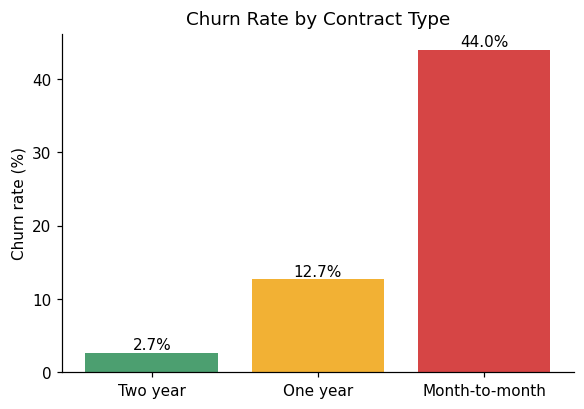

In [20]:
rate = df.groupby("Contract")["ChurnFlag"].mean().mul(100).sort_values()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(rate.index, rate.values, color=["#4C9F70", "#F2B134", "#D64545"])
ax.bar_label(bars, fmt="%.1f%%")
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn Rate by Contract Type")
plt.show()

### 8.2 Tenure distribution: churned vs retained

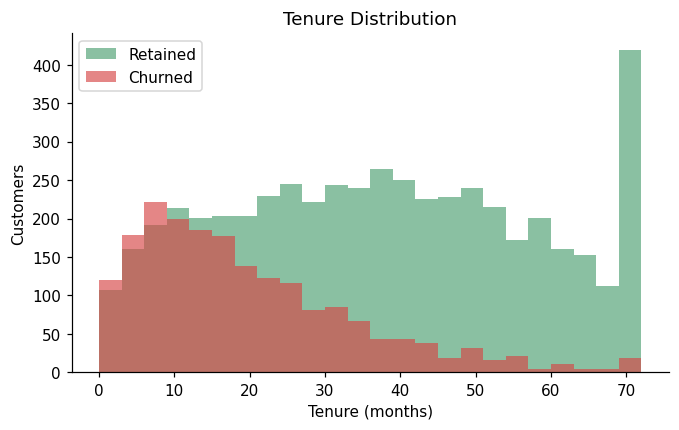

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(retained["tenure"], bins=24, alpha=0.65, label="Retained", color="#4C9F70")
ax.hist(churned["tenure"], bins=24, alpha=0.65, label="Churned", color="#D64545")
ax.set_xlabel("Tenure (months)"); ax.set_ylabel("Customers")
ax.set_title("Tenure Distribution"); ax.legend()
plt.show()

### 8.3 Monthly charges: churned vs retained

/tmp/ipykernel_120/567992401.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([retained["MonthlyCharges"], churned["MonthlyCharges"]],


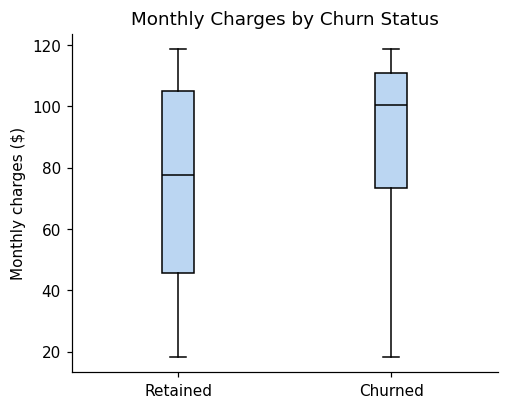

In [22]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot([retained["MonthlyCharges"], churned["MonthlyCharges"]],
           labels=["Retained", "Churned"], patch_artist=True,
           boxprops=dict(facecolor="#BBD6F2"), medianprops=dict(color="black"))
ax.set_ylabel("Monthly charges ($)")
ax.set_title("Monthly Charges by Churn Status")
plt.show()

### 8.4 Share of lost revenue by contract type

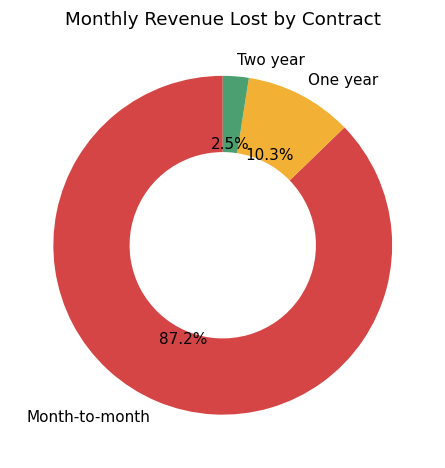

In [23]:
lost_by_contract = churned.groupby("Contract")["MonthlyCharges"].sum()
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(lost_by_contract, labels=lost_by_contract.index, autopct="%1.1f%%", startangle=90,
       wedgeprops=dict(width=0.45), colors=["#D64545", "#F2B134", "#4C9F70"])
ax.set_title("Monthly Revenue Lost by Contract")
plt.show()

## 9. Risk Scoring with NumPy
A simple, explainable rule-based score. Each risk factor adds points:

| Rule | Points |
|---|---|
| Month-to-month contract | +2 |
| Tenure under 12 months | +1 |
| Monthly charges above median | +1 |
| Pays by electronic check | +1 |
| Fiber optic internet | +1 |
| No tech support | +1 |

In [24]:
median_charge = df["MonthlyCharges"].median()

df["RiskScore"] = (
      np.where(df["Contract"] == "Month-to-month", 2, 0)
    + np.where(df["tenure"] < 12, 1, 0)
    + np.where(df["MonthlyCharges"] > median_charge, 1, 0)
    + np.where(df["PaymentMethod"] == "Electronic check", 1, 0)
    + np.where(df["InternetService"] == "Fiber optic", 1, 0)
    + np.where(df["TechSupport"] == "No", 1, 0)
)

conditions = [df["RiskScore"] <= 2, df["RiskScore"].between(3, 4), df["RiskScore"] >= 5]
df["RiskLevel"] = np.select(conditions, ["Low", "Medium", "High"], default="Low")

risk_summary = (df.groupby("RiskLevel")
                  .agg(customers=("ChurnFlag", "size"),
                       churn_rate=("ChurnFlag", lambda s: round(s.mean() * 100, 1)),
                       monthly_revenue=("MonthlyCharges", "sum"))
                  .reindex(["Low", "Medium", "High"]))
risk_summary

,customers,churn_rate,monthly_revenue
RiskLevel,,,
Low,2640,7.8,168730.24
Medium,2877,26.7,239905.40
High,1526,63.6,159084.94


**Validation:** a good score should show churn rising from Low to High.

In [25]:
score_curve = df.groupby("RiskScore")["ChurnFlag"].agg(["size", "mean"])
score_curve["mean"] = (score_curve["mean"] * 100).round(1)
score_curve.columns = ["customers", "churn_rate_%"]
score_curve

,customers,churn_rate_%
RiskScore,,
0,594,2.2
1,776,3.2
2,1270,13.1
3,1697,20.4
4,1180,35.7
5,892,58.2
6,541,69.1
7,93,82.8


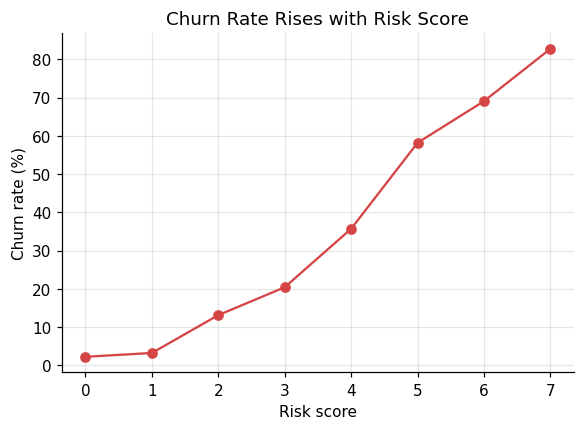

In [26]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(score_curve.index, score_curve["churn_rate_%"], marker="o", color="#D64545")
ax.set_xlabel("Risk score"); ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn Rate Rises with Risk Score"); ax.grid(alpha=0.3)
plt.show()

## 10. Revenue Impact: What If We Reduce Churn?
Scenario: a retention campaign cuts churn by **10%** (relative) among **High-risk** customers.

In [27]:
high = df[df["RiskLevel"] == "High"]
reduction = 0.10

high_churners = high[high["ChurnFlag"] == 1]
customers_saved = len(high_churners) * reduction
monthly_saved = high_churners["MonthlyCharges"].sum() * reduction

print(f"High-risk customers          : {len(high):,}")
print(f"High-risk churners           : {len(high_churners):,}")
print(f"Customers saved (10% cut)    : {customers_saved:,.0f}")
print(f"Monthly revenue saved        : ${monthly_saved:,.0f}")
print(f"Annual revenue saved         : ${monthly_saved * 12:,.0f}")

High-risk customers          : 1,526
High-risk churners           : 970
Customers saved (10% cut)    : 97
Monthly revenue saved        : $10,154
Annual revenue saved         : $121,846


### Sensitivity: how much do we save at different reduction levels?

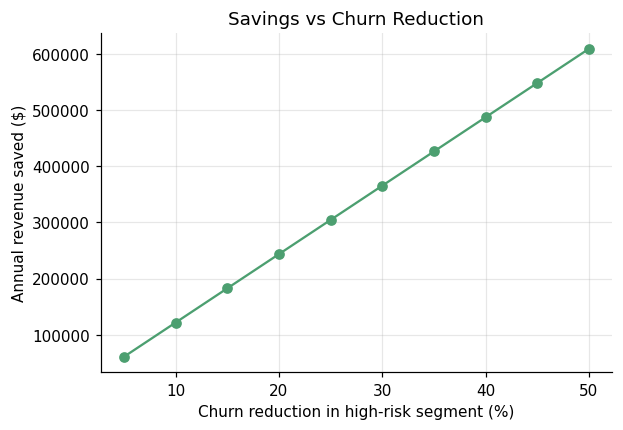

In [28]:
levels = np.arange(0.05, 0.55, 0.05)
annual_saved = high_churners["MonthlyCharges"].sum() * levels * 12

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(levels * 100, annual_saved, marker="o", color="#4C9F70")
ax.set_xlabel("Churn reduction in high-risk segment (%)")
ax.set_ylabel("Annual revenue saved ($)")
ax.set_title("Savings vs Churn Reduction"); ax.grid(alpha=0.3)
plt.show()

## 11. Final Dashboard

/tmp/ipykernel_120/3656974532.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 0].boxplot([retained["MonthlyCharges"], churned["MonthlyCharges"]],


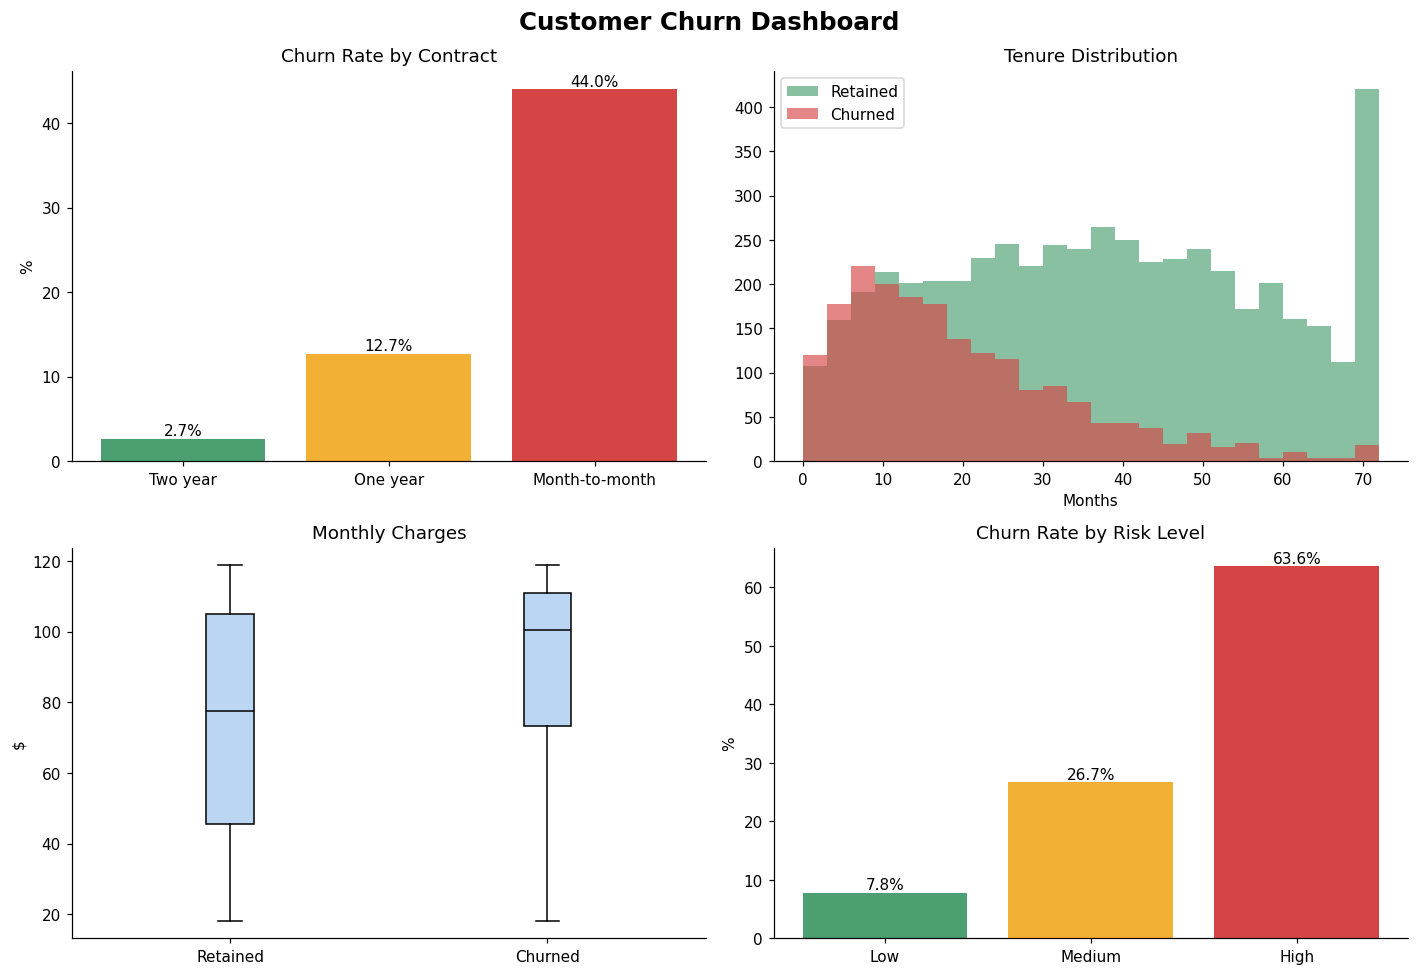

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle("Customer Churn Dashboard", fontsize=16, fontweight="bold")

# 1. churn by contract
rate = df.groupby("Contract")["ChurnFlag"].mean().mul(100).sort_values()
b = axes[0, 0].bar(rate.index, rate.values, color=["#4C9F70", "#F2B134", "#D64545"])
axes[0, 0].bar_label(b, fmt="%.1f%%")
axes[0, 0].set_title("Churn Rate by Contract"); axes[0, 0].set_ylabel("%")

# 2. tenure distribution
axes[0, 1].hist(retained["tenure"], bins=24, alpha=0.65, label="Retained", color="#4C9F70")
axes[0, 1].hist(churned["tenure"], bins=24, alpha=0.65, label="Churned", color="#D64545")
axes[0, 1].set_title("Tenure Distribution"); axes[0, 1].set_xlabel("Months"); axes[0, 1].legend()

# 3. monthly charges boxplot
axes[1, 0].boxplot([retained["MonthlyCharges"], churned["MonthlyCharges"]],
                   labels=["Retained", "Churned"], patch_artist=True,
                   boxprops=dict(facecolor="#BBD6F2"), medianprops=dict(color="black"))
axes[1, 0].set_title("Monthly Charges"); axes[1, 0].set_ylabel("$")

# 4. churn rate by risk level
rl = risk_summary["churn_rate"]
b = axes[1, 1].bar(rl.index, rl.values, color=["#4C9F70", "#F2B134", "#D64545"])
axes[1, 1].bar_label(b, fmt="%.1f%%")
axes[1, 1].set_title("Churn Rate by Risk Level"); axes[1, 1].set_ylabel("%")

plt.tight_layout()
plt.savefig("../images/dashboard.png", bbox_inches="tight")
plt.show()

## 12. Key Findings

In [30]:
worst_contract = df.groupby("Contract")["ChurnFlag"].mean().idxmax()
best_contract = df.groupby("Contract")["ChurnFlag"].mean().idxmin()
first_year_share = churned["tenure"].le(12).mean() * 100
echeck = df[df["PaymentMethod"] == "Electronic check"]["ChurnFlag"].mean() * 100
others = df[df["PaymentMethod"] != "Electronic check"]["ChurnFlag"].mean() * 100

print(f"1. Overall churn rate is {churn_rate:.1f}%, costing ${monthly_revenue_lost:,.0f}/month.")
print(f"2. '{worst_contract}' customers churn most; '{best_contract}' least.")
print(f"3. {first_year_share:.0f}% of churners leave within their first 12 months.")
print(f"4. Electronic-check payers churn at {echeck:.1f}% vs {others:.1f}% for other methods.")
print(f"5. High-risk customers churn at {risk_summary.loc['High','churn_rate']}% vs {risk_summary.loc['Low','churn_rate']}% for low-risk.")

1. Overall churn rate is 27.6%, costing $174,067/month.
2. 'Month-to-month' customers churn most; 'Two year' least.
3. 40% of churners leave within their first 12 months.
4. Electronic-check payers churn at 33.1% vs 24.7% for other methods.
5. High-risk customers churn at 63.6% vs 7.8% for low-risk.


## 13. Business Recommendations
1. **Move customers to longer contracts.** Offer a discount or free add-on for switching from month-to-month to a 1-year plan.
2. **Fix the first year.** Run an onboarding campaign (welcome call, usage tips, check-in at month 3 and 6).
3. **Review the electronic-check experience.** Promote auto-pay with a small bill credit.
4. **Bundle tech support / security.** Customers with these add-ons churn less, so include a free trial for fiber customers.
5. **Operationalise the risk score.** Send the High-risk list to the retention team every month.

## 14. Next Steps
- Replace the rule-based score with logistic regression (scikit-learn) and compare accuracy.
- Simulate a retention campaign with `np.random` to estimate ROI after campaign cost.
- Build a monthly cohort retention curve.